# Actividad 4 · Selección de modelos preentrenados para clasificar claims de etiquetado

Brandon Gilberto Imanol Retana Fuentes - AL07175444

Maestría en Inteligencia Artificial

Gestión de Proyectos de Inteligencia Artificial

Módulo 2

**Objetivo:** Identificar e implementar el modelo preentrenado de Hugging Face más adecuado para clasificar los claims de una etiqueta de alimentos por tipo, de modo que cada claim llegue al checklist de revisión correcto.

## 1. Caso de uso y criterios de selección

**Problema.** Un revisor técnico verifica unas 10,800 etiquetas al año con ~8 claims cada una. Cada tipo de claim se revisa contra reglas distintas, así que el primer paso es saber *qué tipo* de claim es. Hoy esa clasificación es manual. Este módulo la propone automáticamente; el revisor confirma.

| Clase | Qué declara | Ejemplo | Checklist al que se enruta |
|---|---|---|---|
| **NUTRIMENTAL** | Cantidad, presencia, ausencia o comparación de un nutrimento | *Bajo en sodio*, *Sin azúcares añadidos* | Umbrales contra la tabla nutrimental (reglas deterministas) |
| **SALUD** | Relación entre un alimento o nutrimento y la salud o una función del cuerpo | *El calcio es necesario para el mantenimiento de los huesos* | Lista de declaraciones autorizadas y evidencia (mayor riesgo regulatorio) |
| **AUSENCIA** | Ausencia de un alérgeno, aditivo o ingrediente que no es nutrimento | *Sin gluten*, *Sin conservadores* | Evidencia analítica (p. ej., gluten < 20 mg/kg) y control de alérgenos |
| **MARKETING** | Calidad, origen, proceso, sabor o sostenibilidad | *Receta tradicional*, *Hecho en México* | Veracidad y no inducción a error |

**¿Por qué zero-shot con modelos NLI?** No existen todavía claims reales etiquetados para entrenar, las clases las define el área regulatoria en lenguaje natural y pueden cambiar con la norma (basta con editar su descripción), y la inferencia es determinista: el mismo claim siempre recibe la misma clase. Además, los pesos abiertos permiten ejecutar el modelo dentro de la organización, sin enviar etiquetas confidenciales de clientes a una API externa.

### Ecosistema Hugging Face en este proyecto

| Componente | Uso |
|---|---|
| **Models** | Se comparan tres modelos NLI multilingües; su *model card* se consulta por API (licencia, idiomas, descargas, Spaces que los usan) |
| **Datasets** | El CSV se carga y se filtra con la librería `datasets` (`load_dataset`, `filter`) |
| **Spaces** | Ruta de despliegue de una demo del modelo recomendado (`src/app_gradio.py`) para que los revisores lo prueben sin código |
| **Librerías** | `transformers` (pipeline), `evaluate` (métricas), `huggingface_hub` (autenticación y metadatos), `accelerate` |

### Criterios de selección (definidos antes de ejecutar)

| Criterio | Tipo | Cómo se mide | Regla |
|---|---|---|---|
| Tarea compatible | Técnico | `pipeline_tag` en el Hub | zero-shot-classification (NLI) |
| Español | Técnico | Idiomas de entrenamiento (XNLI incluye español) | Obligatorio |
| Desempeño global | Técnico | accuracy, precision, recall y **macro-F1** en test | macro-F1 ≥ 0.80 |
| Seguridad regulatoria | Negocio | **Recall de SALUD** | ≥ 0.90 |
| Latencia | Técnico | ms por claim en T4 (lote y unitario) y en CPU | ≤ 300 ms/claim |
| Costo y recursos | Práctico | Parámetros, tamaño, VRAM, horas de cómputo al año | Menor es mejor |
| Licencia | Práctico | *Model card* | Permite uso comercial |
| Despliegue interno | Práctico | Pesos abiertos, sin API externa | Obligatorio (confidencialidad) |
| Comunidad | Práctico | Descargas, likes, Spaces | Informativo, no decide |

**Modelos candidatos** (misma tarea, tres tamaños, para estudiar el balance precisión–eficiencia):

| Clave | Model ID | Arquitectura |
|---|---|---|
| MiniLM-L6 | `MoritzLaurer/multilingual-MiniLMv2-L6-mnli-xnli` | MiniLMv2, 6 capas (destilado) |
| mDeBERTa-base | `MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7` | mDeBERTa-v3 base, 12 capas |
| XLM-R-large | `joeddav/xlm-roberta-large-xnli` | XLM-RoBERTa large, 24 capas |

Se descartaron modelos solo en inglés, modelos de sentimiento y LLM generativos (mayor costo, salidas no deterministas y más difíciles de auditar en una certificación).

## 2. Configuración de GPU e instalación de dependencias

El entorno de Colab se configuró con GPU en *Entorno de ejecución → Cambiar tipo de entorno de ejecución → T4 GPU*. La celda de importaciones confirma la GPU (`Dispositivo: Tesla T4`, CUDA 13.0) y cada pipeline la usa con `device=0`. Después se instalan las librerías del ecosistema Hugging Face.

In [13]:
%pip install -q transformers datasets evaluate accelerate sentencepiece protobuf huggingface_hub scikit-learn

In [14]:
import gc, inspect, json, platform, random, sys, textwrap, time, warnings
from datetime import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap

import transformers, datasets, sklearn, huggingface_hub
from transformers import pipeline, set_seed
from transformers.utils import logging as hf_logging
from datasets import load_dataset
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix, precision_recall_fscore_support)

try:
    from IPython.display import display
except ImportError:
    display = print

hf_logging.set_verbosity_error()
warnings.filterwarnings("ignore", message=".*pipelines sequentially.*")
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 160)

DEVICE = 0 if torch.cuda.is_available() else -1

try:
    import evaluate
    VERSION_EVALUATE = evaluate.__version__
except ImportError:
    evaluate, VERSION_EVALUATE = None, "no instalado"

print("Python      ", sys.version.split()[0])
print("torch       ", torch.__version__, "| CUDA:", torch.version.cuda)
print("transformers", transformers.__version__)
print("datasets    ", datasets.__version__)
print("evaluate    ", VERSION_EVALUATE)
print("hub         ", huggingface_hub.__version__)
print("scikit-learn", sklearn.__version__)
print("Dispositivo  ", torch.cuda.get_device_name(0) if DEVICE == 0 else "CPU")

Python       3.13.15
torch        2.11.0+cu130 | CUDA: 13.0
transformers 5.18.0
datasets     4.8.5
evaluate     0.4.6
hub          1.33.0
scikit-learn 1.6.1
Dispositivo   Tesla T4


## 3. Autenticación en Hugging Face Hub

El token se lee de los *Secrets* de Colab (`HF_TOKEN`) y nunca se escribe en el código. Si el secreto no existe, la celda lo pide en un campo oculto; si se deja vacío, el notebook continúa sin autenticarse porque los tres modelos son públicos.

In [15]:
import os
from getpass import getpass
from huggingface_hub import login, whoami

token = None
try:
    from google.colab import userdata
    token = userdata.get("HF_TOKEN")
except Exception as e:
    print(f"No se pudo leer HF_TOKEN de los Secrets de Colab ({type(e).__name__}).")

if not token:
    token = os.environ.get("HF_TOKEN")

if not token:
    token = getpass("Pega tu token de Hugging Face (hf_...) o deja vacío para continuar sin autenticación: ").strip() or None

if token:
    os.environ["HF_TOKEN"] = token
    login(token=token)
    print("Autenticado en el Hub como:", whoami()["name"])
else:
    print("Sin HF_TOKEN: se continúa sin autenticación (los modelos son públicos).")

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


Autenticado en el Hub como: BGIRF


## 4. Parámetros del experimento

In [16]:
SEMILLA = 42
random.seed(SEMILLA); np.random.seed(SEMILLA); set_seed(SEMILLA)

# Modelos NLI multilingue para zero-shot
MODELOS = {
    "MiniLM-L6": {
        "id": "MoritzLaurer/multilingual-MiniLMv2-L6-mnli-xnli",
        "arquitectura": "MiniLMv2 (6 capas), destilado de XLM-RoBERTa-large",
        "perfil": "Pequeño: prioriza velocidad y bajo consumo",
    },
    "mDeBERTa-base": {
        "id": "MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7",
        "arquitectura": "mDeBERTa-v3 base (12 capas)",
        "perfil": "Intermedio: preentrenado en 100 idiomas; NLI con 2.7 M de pares en 27 idiomas",
    },
    "XLM-R-large": {
        "id": "joeddav/xlm-roberta-large-xnli",
        "arquitectura": "XLM-RoBERTa large (24 capas)",
        "perfil": "Grande: mayor capacidad, mayor costo",
    },
}

# Clases: Guía de etiquetado
CLASES = ["NUTRIMENTAL", "SALUD", "AUSENCIA", "MARKETING"]

# Configuraciones de ajuste mínimo
CONFIGURACIONES = {
    "base_en": {
        "descripcion": "Sin ajuste: plantilla por defecto (inglés) y el nombre de la clase",
        "plantilla": "This example is {}.",
        "etiquetas": {"NUTRIMENTAL": "nutrimental", "SALUD": "salud",
                      "AUSENCIA": "ausencia", "MARKETING": "marketing"},
    },
    "es_cortas": {
        "descripcion": "Plantilla en español y etiquetas cortas",
        "plantilla": "Esta declaración de etiqueta es de tipo {}.",
        "etiquetas": {"NUTRIMENTAL": "nutrimental", "SALUD": "salud",
                      "AUSENCIA": "ausencia de ingredientes", "MARKETING": "mercadotecnia"},
    },
    "es_descriptivas": {
        "descripcion": "Plantilla en español y etiquetas descritas según la guía de etiquetado",
        "plantilla": "Esta declaración de una etiqueta de alimentos habla de {}.",
        "etiquetas": {
            "NUTRIMENTAL": "la cantidad de un nutrimento como grasa, azúcar, sodio, fibra, proteína, vitaminas o calorías",
            "SALUD": "un beneficio para la salud o una función del cuerpo",
            "AUSENCIA": "la ausencia de un alérgeno, aditivo o ingrediente como gluten, lactosa, conservadores o colorantes",
            "MARKETING": "la calidad, el origen, la elaboración o el sabor del producto",
        },
    },
}

# Umbrales de negocio
UMBRALES = {
    "f1_macro_min": 0.80,          # calidad global
    "recall_salud_min": 0.90,      # no dejar pasar claims de salud (mayor riesgo regulatorio)
    "latencia_gpu_max_ms": 300,    # ms por claim en lote; aprox 8 claims por etiqueta y < 3s por etiqueta
    "precision_auto_min": 0.90,    # exactitud
}
TOLERANCIA_F1 = 0.02
VOLUMEN_ANUAL_CLAIMS = 10_800 * 8

# Parámetros de ejecución
BATCH_SIZE = 16
N_LATENCIA_UNITARIA = 30
MEDIR_CPU = True
N_LATENCIA_CPU = 20
DIR_RESULTADOS = Path("results")
DIR_FIGURAS = DIR_RESULTADOS / "figuras"
DIR_FIGURAS.mkdir(parents=True, exist_ok=True)

# Figuras
COLOR_MODELO = {"MiniLM-L6": "#2a78d6", "mDeBERTa-base": "#eb6834", "XLM-R-large": "#1baf7a"}
COLOR_CONFIG = {"base_en": "#a9a8a1", "es_cortas": "#6f6e69", "es_descriptivas": "#2f2e2b"}
TINTA, TINTA_2, REJILLA, SUPERFICIE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SUPERFICIE, "axes.facecolor": SUPERFICIE, "savefig.facecolor": SUPERFICIE,
    "axes.edgecolor": REJILLA, "axes.labelcolor": TINTA_2, "text.color": TINTA,
    "xtick.color": TINTA_2, "ytick.color": TINTA_2, "font.size": 10,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 200,
})
print("Modelos:", ", ".join(MODELOS))
print("Configuraciones de ajuste:", ", ".join(CONFIGURACIONES))
print("Umbrales:", UMBRALES)

Modelos: MiniLM-L6, mDeBERTa-base, XLM-R-large
Configuraciones de ajuste: base_en, es_cortas, es_descriptivas
Umbrales: {'f1_macro_min': 0.8, 'recall_salud_min': 0.9, 'latencia_gpu_max_ms': 300, 'precision_auto_min': 0.9}


## 5. Dataset

Dataset propio de 240 claims en español (`data/claims_etiquetado.csv`), redactados a partir de la estructura de los marcos UE (Reg. 1924/2006, 432/2012, 828/2014, 1169/2011), FDA (21 CFR 101) y NOM-051.

In [17]:
import urllib.request

URL_DATASET = ""
CANDIDATAS = [Path("data/claims_etiquetado.csv"), Path("claims_etiquetado.csv"),
              Path("/content/clasificacion-claims-etiquetado/data/claims_etiquetado.csv")]

ruta = next((p for p in CANDIDATAS if p.exists()), None)
if ruta is None and URL_DATASET:
    ruta = Path("data/claims_etiquetado.csv"); ruta.parent.mkdir(exist_ok=True)
    urllib.request.urlretrieve(URL_DATASET, ruta)
if ruta is None:
    try:
        from google.colab import files
        print("Sube el archivo data/claims_etiquetado.csv del repositorio:")
        ruta = Path(next(iter(files.upload())))
    except ImportError:
        raise FileNotFoundError("No se encontró claims_etiquetado.csv: colócalo en data/ o define URL_DATASET.")

# Carga con la librería Datasets de Hugging Face
ds = load_dataset("csv", data_files=str(ruta), split="train")
print(ds)
print(ds.features)

Dataset({
    features: ['id_claim', 'texto_claim', 'categoria', 'subtipo', 'referencia_normativa', 'dificultad', 'origen_registro', 'n_palabras', 'particion'],
    num_rows: 240
})
{'id_claim': Value('string'), 'texto_claim': Value('string'), 'categoria': Value('string'), 'subtipo': Value('string'), 'referencia_normativa': Value('string'), 'dificultad': Value('string'), 'origen_registro': Value('string'), 'n_palabras': Value('int64'), 'particion': Value('string')}


In [18]:
df = ds.to_pandas()
ds_dev = ds.filter(lambda x: x["particion"] == "dev")
ds_test = ds.filter(lambda x: x["particion"] == "test")
df_dev, df_test = ds_dev.to_pandas(), ds_test.to_pandas()
textos_dev, y_dev = df_dev["texto_claim"].tolist(), df_dev["categoria"].to_numpy()
textos_test, y_test = df_test["texto_claim"].tolist(), df_test["categoria"].to_numpy()

# Controles de calidad del dataset
assert set(df["categoria"]) == set(CLASES), "Hay clases fuera de la guía"
assert df["texto_claim"].notna().all() and df["id_claim"].is_unique
assert not df["texto_claim"].str.lower().duplicated().any(), "Hay claims duplicados"
print(f"{len(df)} claims · dev = {len(df_dev)} · test = {len(df_test)} · sin nulos ni duplicados ✓")

240 claims · dev = 71 · test = 169 · sin nulos ni duplicados ✓


Distribución por clase y partición


particion,dev,test,Total
categoria,,,
NUTRIMENTAL,21,49,70
SALUD,18,42,60
AUSENCIA,16,39,55
MARKETING,16,39,55
Total,71,169,240



Casos frontera (dificultad) y origen del registro


dificultad        ambiguo                   estandar                 
origen_registro plantilla redaccion_manual plantilla redaccion_manual
categoria                                                            
NUTRIMENTAL             0               10        35               25
SALUD                  10                8        13               29
AUSENCIA                0                8        29               18
MARKETING               0                7        20               28


Longitud del claim (palabras)


,mean,min,max
categoria,,,
NUTRIMENTAL,5.4,1.0,13.0
SALUD,10.2,3.0,22.0
AUSENCIA,3.5,1.0,7.0
MARKETING,4.1,2.0,12.0



Ejemplos por clase


,id_claim,texto_claim,categoria,subtipo,dificultad
0,CLM-0001,Muy bajo en sal,NUTRIMENTAL,contenido_bajo_o_sin,estandar
1,CLM-0002,"0 % conservadores, 100 % sabor",AUSENCIA,aditivo,ambiguo
2,CLM-0003,Pan de caja con 30 % menos azúcar,NUTRIMENTAL,comparativa,estandar
3,CLM-0004,No contiene huevo ni lácteos,AUSENCIA,alergeno_intolerancia,estandar
4,CLM-0005,Hecho en Puebla,MARKETING,marketing,estandar
5,CLM-0006,Mejora tu concentración,SALUD,beneficio_generico,estandar
7,CLM-0008,Empaque 100 % reciclable,MARKETING,marketing,estandar
8,CLM-0009,"Fuente de calcio, que ayuda a mantener huesos fuertes",SALUD,funcion_nutrimento,ambiguo


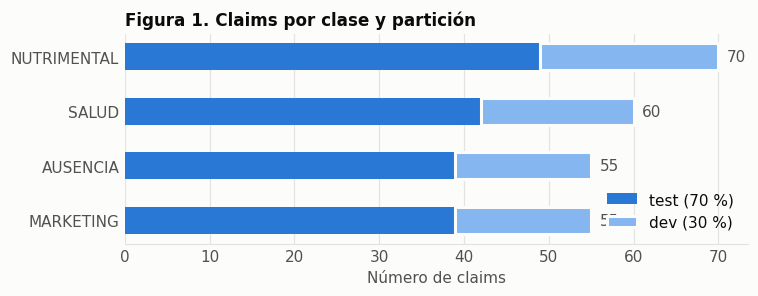

In [19]:
print("Distribución por clase y partición")
display(pd.crosstab(df["categoria"], df["particion"], margins=True, margins_name="Total").reindex(CLASES + ["Total"]))
print("\nCasos frontera (dificultad) y origen del registro")
display(pd.crosstab(df["categoria"], [df["dificultad"], df["origen_registro"]]).reindex(CLASES))
print("\nLongitud del claim (palabras)")
display(df.groupby("categoria")["n_palabras"].describe()[["mean", "min", "max"]].reindex(CLASES).round(1))
print("\nEjemplos por clase")
display(df.groupby("categoria").head(2)[["id_claim", "texto_claim", "categoria", "subtipo", "dificultad"]])

conteo = pd.crosstab(df["categoria"], df["particion"]).reindex(CLASES[::-1])
fig, ax = plt.subplots(figsize=(7, 2.8))
yy = np.arange(len(conteo))
ax.barh(yy, conteo["test"], height=0.5, color="#2a78d6", label="test (70 %)")
ax.barh(yy, conteo["dev"], left=conteo["test"], height=0.5, color="#86b6ef", label="dev (30 %)",
        edgecolor=SUPERFICIE, linewidth=2)
for i, tot in enumerate(conteo.sum(axis=1)):
    ax.text(tot + 1, i, str(tot), va="center", color=TINTA_2)
ax.set_yticks(yy, conteo.index); ax.set_xlabel("Número de claims")
ax.set_title("Figura 1. Claims por clase y partición")
ax.grid(axis="x", color=REJILLA, linewidth=0.8); ax.set_axisbelow(True)
for s in ("top", "right", "left"): ax.spines[s].set_visible(False)
ax.tick_params(length=0); ax.legend(loc="lower right")
fig.tight_layout(); fig.savefig(DIR_FIGURAS / "fig1_distribucion_clases.png"); plt.show()

## 6. Pipeline de inferencia y funciones de evaluación

- El `pipeline("zero-shot-classification")` convierte cada claim en un par premisa–hipótesis por clase (*"Esta declaración… habla de {descripción de la clase}"*) y asigna la clase cuya hipótesis tiene la mayor probabilidad de implicación (*entailment*).

- Se usa **macro-F1** porque las clases tienen el mismo peso de negocio aunque no el mismo tamaño.

In [20]:
_PARAMS_PIPELINE = inspect.signature(pipeline).parameters
_METRICAS_HF = {}
if evaluate is not None:
    try:
        _METRICAS_HF = {"accuracy": evaluate.load("accuracy"), "f1": evaluate.load("f1")}
    except Exception as e:
        print("evaluate no pudo descargar las métricas; se usa solo scikit-learn:", str(e)[:80])


def _sync():
    if torch.cuda.is_available():
        torch.cuda.synchronize()


def cargar_clasificador(model_id, device=DEVICE, fp16=False):
    """Carga el pipeline zero-shot (descarga pesos y tokenizador desde el Hub)."""
    kwargs = {}
    if fp16:
        kwargs["dtype" if "dtype" in _PARAMS_PIPELINE else "torch_dtype"] = torch.float16
    t0 = time.perf_counter()
    clf = pipeline("zero-shot-classification", model=model_id, device=device, **kwargs)
    return clf, time.perf_counter() - t0


def clasificar(clf, textos, config, batch_size=BATCH_SIZE):
    """Inferencia: devuelve clase predicha, confianza y probabilidad de cada clase."""
    etiquetas = config["etiquetas"]
    verbal_a_clase = {v: k for k, v in etiquetas.items()}
    salidas = clf(list(textos), candidate_labels=[etiquetas[c] for c in CLASES],
                  hypothesis_template=config["plantilla"], multi_label=False, batch_size=batch_size)
    if isinstance(salidas, dict):
        salidas = [salidas]
    filas = []
    for s in salidas:
        p = {verbal_a_clase[l]: float(v) for l, v in zip(s["labels"], s["scores"])}
        pred = max(p, key=p.get)
        filas.append({"pred": pred, "confianza": p[pred], **{f"p_{c}": p[c] for c in CLASES}})
    return pd.DataFrame(filas)


def calcular_metricas(y_true, y_pred):
    """accuracy + precision/recall/F1 macro (clases con el mismo peso) y por clase."""
    y_true, y_pred = list(y_true), list(y_pred)
    acc = accuracy_score(y_true, y_pred)
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_pred, labels=CLASES, average="macro", zero_division=0)
    pc, rc, fc, sc = precision_recall_fscore_support(y_true, y_pred, labels=CLASES, average=None, zero_division=0)
    por_clase = pd.DataFrame({"precision": pc, "recall": rc, "f1": fc, "soporte": sc}, index=CLASES)
    return {"accuracy": acc, "precision_macro": p, "recall_macro": r, "f1_macro": f1}, por_clase


def cotejar_con_evaluate(y_true, y_pred, metricas):
    """Comprueba que la librería evaluate de Hugging Face da los mismos valores."""
    if not _METRICAS_HF:
        return
    idx = {c: i for i, c in enumerate(CLASES)}
    refs, preds = [idx[c] for c in y_true], [idx[c] for c in y_pred]
    acc = _METRICAS_HF["accuracy"].compute(predictions=preds, references=refs)["accuracy"]
    f1 = _METRICAS_HF["f1"].compute(predictions=preds, references=refs, average="macro")["f1"]
    ok = abs(acc - metricas["accuracy"]) < 1e-9 and abs(f1 - metricas["f1_macro"]) < 1e-9
    print(f"    Cotejo con evaluate → accuracy {acc:.3f} · F1 macro {f1:.3f} {'✓ coincide' if ok else '✗ difiere'}")


def elegir_umbral(confianza, correcto, meta=UMBRALES["precision_auto_min"]):
    """Menor τ cuya exactitud en lo automatizado (confianza ≥ τ) alcanza la meta → máxima cobertura."""
    confianza, correcto = np.asarray(confianza), np.asarray(correcto, dtype=bool)
    for tau in np.round(np.arange(0.25, 1.0, 0.05), 2):
        m = confianza >= tau
        if m.sum() >= 5 and correcto[m].mean() >= meta:
            return float(tau)
    return None


def cobertura_y_exactitud(confianza, correcto, tau):
    if tau is None:
        return 0.0, float("nan")
    m = np.asarray(confianza) >= tau
    return float(m.mean()), (float(np.asarray(correcto)[m].mean()) if m.any() else float("nan"))


def medir_latencia_lote(clf, textos, config, batch_size=BATCH_SIZE):
    _sync(); t0 = time.perf_counter()
    pred = clasificar(clf, textos, config, batch_size)
    _sync(); total = time.perf_counter() - t0
    return pred, total, 1000 * total / len(textos)


def medir_latencia_unitaria(clf, textos, config):
    tiempos = []
    for t in textos:
        _sync(); t0 = time.perf_counter()
        clasificar(clf, [t], config, batch_size=1)
        _sync(); tiempos.append(1000 * (time.perf_counter() - t0))
    return float(np.percentile(tiempos, 50)), float(np.percentile(tiempos, 95)), float(np.mean(tiempos))


def liberar():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()


def evaluar_modelo(clave):
    info = MODELOS[clave]
    print(f"══ {clave} · {info['id']}\n   {info['arquitectura']} — {info['perfil']}")
    if torch.cuda.is_available():
        torch.cuda.empty_cache(); torch.cuda.reset_peak_memory_stats()

    # Carga del modelo preentrenado
    clf, t_carga = cargar_clasificador(info["id"])
    n_params = sum(p.numel() for p in clf.model.parameters())
    print(f"[1] Carga: {n_params / 1e6:.0f} M parámetros · {t_carga:.1f} s")
    clasificar(clf, textos_dev[:8], CONFIGURACIONES["es_descriptivas"])

    # Ajuste
    filas, preds_dev = [], {}
    for nombre, cfg in CONFIGURACIONES.items():
        d = clasificar(clf, textos_dev, cfg)
        m, _ = calcular_metricas(y_dev, d["pred"])
        filas.append({"modelo": clave, "configuracion": nombre, **m})
        preds_dev[nombre] = d
    ablacion = pd.DataFrame(filas)
    elegida = ablacion.sort_values(["f1_macro", "accuracy"], ascending=False).iloc[0]["configuracion"]
    print("[2] Ajuste mínimo en dev (macro-F1 por configuración):")
    display(ablacion.drop(columns="modelo").set_index("configuracion").round(3))
    cfg = CONFIGURACIONES[elegida]
    d = preds_dev[elegida]
    tau = elegir_umbral(d["confianza"], d["pred"].to_numpy() == y_dev)
    print(f"    → Configuración elegida: «{elegida}» · umbral de confianza τ = {tau}")

    # Evaluación final en test
    pred_test, t_total, ms_claim = medir_latencia_lote(clf, textos_test, cfg)
    metricas, por_clase = calcular_metricas(y_test, pred_test["pred"])
    base = clasificar(clf, textos_test, CONFIGURACIONES["base_en"])
    f1_base = calcular_metricas(y_test, base["pred"])[0]["f1_macro"]
    correcto = pred_test["pred"].to_numpy() == y_test
    cobertura, acc_auto = cobertura_y_exactitud(pred_test["confianza"], correcto, tau)
    cm = confusion_matrix(y_test, pred_test["pred"], labels=CLASES)
    print(f"[3] Test (n = {len(y_test)}): accuracy {metricas['accuracy']:.3f} · precision {metricas['precision_macro']:.3f}"
          f" · recall {metricas['recall_macro']:.3f} · F1 macro {metricas['f1_macro']:.3f}")
    cotejar_con_evaluate(y_test, pred_test["pred"], metricas)
    print(classification_report(y_test, pred_test["pred"], labels=CLASES, digits=3, zero_division=0))

    # Latencia unitaria y memoria
    p50, p95, _ = medir_latencia_unitaria(clf, textos_test[:N_LATENCIA_UNITARIA], cfg)
    vram = torch.cuda.max_memory_allocated() / 2**20 if torch.cuda.is_available() else float("nan")
    print(f"[4] Latencia: {ms_claim:.1f} ms/claim en lote · unitaria p50 {p50:.1f} ms · p95 {p95:.1f} ms"
          + (f" · VRAM pico {vram:.0f} MB" if not np.isnan(vram) else " · (CPU, sin VRAM)"))

    ms_cpu = float("nan")
    if DEVICE == -1:
        ms_cpu = ms_claim
    elif MEDIR_CPU:
        clf_cpu = pipeline("zero-shot-classification", model=clf.model.to("cpu"), tokenizer=clf.tokenizer, device=-1)
        _, _, ms_cpu = medir_latencia_unitaria(clf_cpu, textos_test[:N_LATENCIA_CPU], cfg)
        print(f"[5] CPU: {ms_cpu:.0f} ms/claim (media de {N_LATENCIA_CPU} claims, uno a la vez)")
        del clf_cpu
    del clf
    liberar()

    pred_test = pd.concat([df_test[["id_claim", "texto_claim", "categoria", "subtipo", "dificultad",
                                    "origen_registro"]].reset_index(drop=True), pred_test], axis=1)
    pred_test.insert(0, "modelo", clave)
    return {
        "clave": clave, "model_id": info["id"], "arquitectura": info["arquitectura"],
        "params_M": n_params / 1e6, "t_carga_s": t_carga, "config": elegida, "tau": tau,
        "ablacion": ablacion, "metricas": metricas, "por_clase": por_clase, "cm": cm,
        "f1_base_test": f1_base, "pred_test": pred_test, "cobertura_auto": cobertura,
        "exactitud_auto": acc_auto, "ms_claim_gpu": ms_claim if DEVICE == 0 else float("nan"),
        "t_total_test_s": t_total, "p50_ms": p50, "p95_ms": p95, "ms_claim_cpu": ms_cpu, "vram_MB": vram,
        "dispositivo": torch.cuda.get_device_name(0) if DEVICE == 0 else "CPU",
    }


def conclusion_parcial(r):
    m, u = r["metricas"], UMBRALES
    ok = lambda c: "✓" if c else "✗"
    rec_salud = r["por_clase"].loc["SALUD", "recall"]
    cm = r["cm"].copy(); np.fill_diagonal(cm, 0)
    i, j = np.unravel_index(cm.argmax(), cm.shape)
    abl = r["ablacion"].set_index("configuracion")["f1_macro"]
    lineas = [
        f"Ajuste mínimo: «{r['config']}» fue la mejor configuración en dev (F1 {abl[r['config']]:.2f} vs "
        f"{abl['base_en']:.2f} sin ajuste); en test el ajuste cambia el macro-F1 en {m['f1_macro'] - r['f1_base_test']:+.2f}.",
        f"Desempeño en test: accuracy {m['accuracy']:.2f}, precision {m['precision_macro']:.2f}, recall "
        f"{m['recall_macro']:.2f} y macro-F1 {m['f1_macro']:.2f} {ok(m['f1_macro'] >= u['f1_macro_min'])} (meta ≥ {u['f1_macro_min']}).",
        f"Recall de SALUD: {rec_salud:.2f} {ok(rec_salud >= u['recall_salud_min'])} (meta ≥ {u['recall_salud_min']}).",
        (f"Confusión más frecuente: {CLASES[i]} → {CLASES[j]} ({cm[i, j]} claims)." if cm.max() > 0
         else "Sin confusiones entre clases en test."),
        (f"Eficiencia: {r['ms_claim_gpu']:.1f} ms/claim en lote GPU, p95 unitario {r['p95_ms']:.0f} ms, "
         f"{r['ms_claim_cpu']:.0f} ms/claim en CPU, VRAM pico {r['vram_MB']:.0f} MB, {r['params_M']:.0f} M parámetros."
         if not np.isnan(r["ms_claim_gpu"]) else
         f"Eficiencia (sin GPU): {r['ms_claim_cpu']:.1f} ms/claim en CPU, p95 unitario {r['p95_ms']:.0f} ms, "
         f"{r['params_M']:.0f} M parámetros."),
        (f"Umbral τ = {r['tau']:.2f} (elegido en dev): automatizaría el {r['cobertura_auto']:.0%} de test con "
         f"exactitud {r['exactitud_auto']:.0%}; el resto va a revisión humana." if r["tau"] is not None
         else "Ningún umbral alcanza la exactitud exigida en dev: todo claim iría a revisión humana."),
    ]
    print(f"Conclusión parcial · {r['clave']}")
    for linea in lineas:
        print(textwrap.fill("• " + linea, 110, subsequent_indent="  "))


RESULTADOS = {}

## 7. Implementación de los tres modelos

### 7.1 Metadatos de los modelos en el Hub (model cards)

In [21]:
def metadatos_hub(model_id):
    try:
        info = huggingface_hub.HfApi().model_info(model_id, files_metadata=True)
    except Exception as e:
        return {"model_id": model_id, "licencia": "n/d", "error": str(e)[:60]}
    card = info.card_data.to_dict() if info.card_data else {}
    archivos = info.siblings or []
    pesos = ([s for s in archivos if s.rfilename.endswith(".safetensors")]
             or [s for s in archivos if s.rfilename.endswith(".bin")])
    idiomas = card.get("language") or []
    idiomas = idiomas if isinstance(idiomas, list) else [idiomas]
    return {
        "model_id": model_id, "licencia": card.get("license", "n/d"), "tarea_hub": info.pipeline_tag,
        "n_idiomas_card": len(idiomas), "incluye_es": "es" in idiomas,
        "tamano_disco_MB": round(sum((s.size or 0) for s in pesos) / 2**20) if pesos else None,
        "descargas_mes": info.downloads, "likes": info.likes,
        "spaces_que_lo_usan": len(info.spaces or []), "commit": (info.sha or "")[:10],
    }

META = pd.DataFrame([{"modelo": k, **metadatos_hub(v["id"])} for k, v in MODELOS.items()]).set_index("modelo")
display(META)

,model_id,licencia,tarea_hub,n_idiomas_card,incluye_es,tamano_disco_MB,descargas_mes,likes,spaces_que_lo_usan,commit
modelo,,,,,,,,,,
MiniLM-L6,MoritzLaurer/multilingual-MiniLMv2-L6-mnli-xnli,mit,zero-shot-classification,16,True,408,19480,52,17,0a71e92a98
mDeBERTa-base,MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7,mit,zero-shot-classification,27,True,532,884409,394,53,b5113eb38a
XLM-R-large,joeddav/xlm-roberta-large-xnli,mit,zero-shot-classification,16,True,2140,2010957,293,98,b227ee8435


### 7.2 Modelo A - MiniLM-L6 (pequeño)

`MoritzLaurer/multilingual-MiniLMv2-L6-mnli-xnli`: versión destilada (MiniLMv2) de XLM-RoBERTa-large con 6 capas, entrenada en MNLI y XNLI.

- Podría ser el modelo más rápido y ligero, con posible pérdida de precisión en los casos frontera.

In [22]:
RESULTADOS["MiniLM-L6"] = evaluar_modelo("MiniLM-L6")

══ MiniLM-L6 · MoritzLaurer/multilingual-MiniLMv2-L6-mnli-xnli
   MiniLMv2 (6 capas), destilado de XLM-RoBERTa-large — Pequeño: prioriza velocidad y bajo consumo


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

[1] Carga: 107 M parámetros · 11.6 s
[2] Ajuste mínimo en dev (macro-F1 por configuración):


,accuracy,precision_macro,recall_macro,f1_macro
configuracion,,,,
base_en,0.465,0.366,0.449,0.365
es_cortas,0.451,0.437,0.441,0.400
es_descriptivas,0.592,0.684,0.575,0.569


    → Configuración elegida: «es_descriptivas» · umbral de confianza τ = 0.5
[3] Test (n = 169): accuracy 0.550 · precision 0.679 · recall 0.544 · F1 macro 0.537
    Cotejo con evaluate → accuracy 0.550 · F1 macro 0.537 ✓ coincide
              precision    recall  f1-score   support

 NUTRIMENTAL      0.528     0.571     0.549        49
       SALUD      0.850     0.810     0.829        42
    AUSENCIA      1.000     0.205     0.340        39
   MARKETING      0.338     0.590     0.430        39

    accuracy                          0.550       169
   macro avg      0.679     0.544     0.537       169
weighted avg      0.673     0.550     0.543       169

[4] Latencia: 13.9 ms/claim en lote · unitaria p50 79.1 ms · p95 107.9 ms · VRAM pico 435 MB
[5] CPU: 377 ms/claim (media de 20 claims, uno a la vez)


In [23]:
conclusion_parcial(RESULTADOS["MiniLM-L6"])

Conclusión parcial · MiniLM-L6
• Ajuste mínimo: «es_descriptivas» fue la mejor configuración en dev (F1 0.57 vs 0.37 sin ajuste); en test el
  ajuste cambia el macro-F1 en +0.09.
• Desempeño en test: accuracy 0.55, precision 0.68, recall 0.54 y macro-F1 0.54 ✗ (meta ≥ 0.8).
• Recall de SALUD: 0.81 ✗ (meta ≥ 0.9).
• Confusión más frecuente: AUSENCIA → MARKETING (25 claims).
• Eficiencia: 13.9 ms/claim en lote GPU, p95 unitario 108 ms, 377 ms/claim en CPU, VRAM pico 435 MB, 107 M
  parámetros.
• Umbral τ = 0.50 (elegido en dev): automatizaría el 20% de test con exactitud 97%; el resto va a revisión
  humana.


### 7.3 Modelo B - mDeBERTa-v3 base (intermedio)

`MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7`: mDeBERTa-v3 base ajustado con XNLI y 2.7 millones de pares NLI en 27 idiomas.

- Podría ser el más balanceado, por su entrenamiento NLI más amplio en idiomas diferentes al inglés.

In [24]:
RESULTADOS["mDeBERTa-base"] = evaluar_modelo("mDeBERTa-base")

══ mDeBERTa-base · MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7
   mDeBERTa-v3 base (12 capas) — Intermedio: preentrenado en 100 idiomas; NLI con 2.7 M de pares en 27 idiomas


Loading weights:   0%|          | 0/202 [00:00<?, ?it/s]

[1] Carga: 279 M parámetros · 3.9 s
[2] Ajuste mínimo en dev (macro-F1 por configuración):


,accuracy,precision_macro,recall_macro,f1_macro
configuracion,,,,
base_en,0.493,0.572,0.502,0.459
es_cortas,0.563,0.587,0.577,0.533
es_descriptivas,0.493,0.533,0.499,0.482


    → Configuración elegida: «es_cortas» · umbral de confianza τ = None
[3] Test (n = 169): accuracy 0.609 · precision 0.659 · recall 0.623 · F1 macro 0.599
    Cotejo con evaluate → accuracy 0.609 · F1 macro 0.599 ✓ coincide
              precision    recall  f1-score   support

 NUTRIMENTAL      0.516     0.327     0.400        49
       SALUD      0.500     0.857     0.632        42
    AUSENCIA      0.729     0.897     0.805        39
   MARKETING      0.889     0.410     0.561        39

    accuracy                          0.609       169
   macro avg      0.659     0.623     0.599       169
weighted avg      0.647     0.609     0.588       169

[4] Latencia: 36.8 ms/claim en lote · unitaria p50 342.3 ms · p95 575.2 ms · VRAM pico 630 MB
[5] CPU: 10642 ms/claim (media de 20 claims, uno a la vez)


In [25]:
conclusion_parcial(RESULTADOS["mDeBERTa-base"])

Conclusión parcial · mDeBERTa-base
• Ajuste mínimo: «es_cortas» fue la mejor configuración en dev (F1 0.53 vs 0.46 sin ajuste); en test el ajuste
  cambia el macro-F1 en +0.04.
• Desempeño en test: accuracy 0.61, precision 0.66, recall 0.62 y macro-F1 0.60 ✗ (meta ≥ 0.8).
• Recall de SALUD: 0.86 ✗ (meta ≥ 0.9).
• Confusión más frecuente: NUTRIMENTAL → SALUD (27 claims).
• Eficiencia: 36.8 ms/claim en lote GPU, p95 unitario 575 ms, 10642 ms/claim en CPU, VRAM pico 630 MB, 279 M
  parámetros.
• Ningún umbral alcanza la exactitud exigida en dev: todo claim iría a revisión humana.


### 7.4 Modelo C - XLM-RoBERTa large (grande)

`joeddav/xlm-roberta-large-xnli`: XLM-RoBERTa large ajustado en MNLI y XNLI; el modelo zero-shot multilingüe de referencia en el Hub.

- Modelo con mayor capacidad, a costa de más latencia, memoria y costo.

In [26]:
RESULTADOS["XLM-R-large"] = evaluar_modelo("XLM-R-large")

══ XLM-R-large · joeddav/xlm-roberta-large-xnli
   XLM-RoBERTa large (24 capas) — Grande: mayor capacidad, mayor costo


config.json:   0%|          | 0.00/734 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.24GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/393 [00:00<?, ?it/s]

...

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/150 [00:00<?, ?B/s]

[1] Carga: 560 M parámetros · 39.1 s
[2] Ajuste mínimo en dev (macro-F1 por configuración):


,accuracy,precision_macro,recall_macro,f1_macro
configuracion,,,,
base_en,0.521,0.489,0.508,0.431
es_cortas,0.577,0.712,0.571,0.548
es_descriptivas,0.479,0.605,0.476,0.446


    → Configuración elegida: «es_cortas» · umbral de confianza τ = None
[3] Test (n = 169): accuracy 0.615 · precision 0.718 · recall 0.610 · F1 macro 0.592
    Cotejo con evaluate → accuracy 0.615 · F1 macro 0.592 ✓ coincide
              precision    recall  f1-score   support

 NUTRIMENTAL      0.476     0.796     0.595        49
       SALUD      0.706     0.286     0.407        42
    AUSENCIA      0.691     0.974     0.809        39
   MARKETING      1.000     0.385     0.556        39

    accuracy                          0.615       169
   macro avg      0.718     0.610     0.592       169
weighted avg      0.704     0.615     0.589       169

[4] Latencia: 23.1 ms/claim en lote · unitaria p50 70.0 ms · p95 93.1 ms · VRAM pico 2187 MB
[5] CPU: 1810 ms/claim (media de 20 claims, uno a la vez)


In [27]:
conclusion_parcial(RESULTADOS["XLM-R-large"])

Conclusión parcial · XLM-R-large
• Ajuste mínimo: «es_cortas» fue la mejor configuración en dev (F1 0.55 vs 0.43 sin ajuste); en test el ajuste
  cambia el macro-F1 en +0.14.
• Desempeño en test: accuracy 0.62, precision 0.72, recall 0.61 y macro-F1 0.59 ✗ (meta ≥ 0.8).
• Recall de SALUD: 0.29 ✗ (meta ≥ 0.9).
• Confusión más frecuente: SALUD → NUTRIMENTAL (30 claims).
• Eficiencia: 23.1 ms/claim en lote GPU, p95 unitario 93 ms, 1810 ms/claim en CPU, VRAM pico 2187 MB, 560 M
  parámetros.
• Ningún umbral alcanza la exactitud exigida en dev: todo claim iría a revisión humana.


## 8. Comparación del desempeño

- La tabla reúne métricas, latencia, recursos y el cumplimiento de cada umbral.

- Las figuras muestran el efecto del ajuste mínimo, el balance precisión–eficiencia, el recall por clase, las confusiones y cuánto se puede automatizar sin perder exactitud.

In [28]:
def fila_comparativa(r):
    meta = META.loc[r["clave"]] if r["clave"] in META.index else {}
    m = r["metricas"]
    rec_salud = r["por_clase"].loc["SALUD", "recall"]
    lat = r["ms_claim_gpu"] if not np.isnan(r["ms_claim_gpu"]) else r["ms_claim_cpu"]
    return {
        "modelo": r["clave"], "model_id": r["model_id"], "arquitectura": r["arquitectura"],
        "params_M": round(r["params_M"]), "tamano_disco_MB": meta.get("tamano_disco_MB"),
        "licencia": meta.get("licencia"), "config_ajuste": r["config"],
        "accuracy": m["accuracy"], "precision_macro": m["precision_macro"], "recall_macro": m["recall_macro"],
        "f1_macro": m["f1_macro"], "f1_macro_sin_ajuste": r["f1_base_test"], "recall_salud": rec_salud,
        "ms_claim_gpu": r["ms_claim_gpu"], "p95_unitario_ms": r["p95_ms"], "ms_claim_cpu": r["ms_claim_cpu"],
        "vram_MB": r["vram_MB"],
        "horas_gpu_anuales": VOLUMEN_ANUAL_CLAIMS * r["ms_claim_gpu"] / 3.6e6,
        "horas_cpu_anuales": VOLUMEN_ANUAL_CLAIMS * r["ms_claim_cpu"] / 3.6e6,
        "tau": r["tau"], "cobertura_auto": r["cobertura_auto"], "exactitud_auto": r["exactitud_auto"],
        "cumple_f1": m["f1_macro"] >= UMBRALES["f1_macro_min"],
        "cumple_recall_salud": rec_salud >= UMBRALES["recall_salud_min"],
        "cumple_latencia": lat <= UMBRALES["latencia_gpu_max_ms"],
        "dispositivo": r["dispositivo"],
    }

comparativo = pd.DataFrame([fila_comparativa(RESULTADOS[k]) for k in RESULTADOS]).set_index("modelo")
comparativo["cumple_todo"] = comparativo[["cumple_f1", "cumple_recall_salud", "cumple_latencia"]].all(axis=1)
ablacion_dev = pd.concat([RESULTADOS[k]["ablacion"] for k in RESULTADOS], ignore_index=True)
por_clase = pd.concat({k: RESULTADOS[k]["por_clase"] for k in RESULTADOS}, names=["modelo", "clase"])
predicciones = pd.concat([RESULTADOS[k]["pred_test"] for k in RESULTADOS], ignore_index=True)

print("Tabla comparativa (partición test)")
display(comparativo[["params_M", "tamano_disco_MB", "licencia", "config_ajuste", "accuracy", "precision_macro",
                     "recall_macro", "f1_macro", "recall_salud", "ms_claim_gpu", "p95_unitario_ms",
                     "ms_claim_cpu", "vram_MB"]].round(3))
print("Eficiencia a volumen anual y umbral de automatización")
display(comparativo[["horas_gpu_anuales", "horas_cpu_anuales", "tau", "cobertura_auto", "exactitud_auto",
                     "cumple_f1", "cumple_recall_salud", "cumple_latencia", "cumple_todo"]].round(3))
print("Métricas por clase")
display(por_clase.unstack("clase")["recall"].round(3).rename_axis(columns="recall por clase"))

Tabla comparativa (partición test)


,params_M,tamano_disco_MB,licencia,config_ajuste,accuracy,precision_macro,recall_macro,f1_macro,recall_salud,ms_claim_gpu,p95_unitario_ms,ms_claim_cpu,vram_MB
modelo,,,,,,,,,,,,,
MiniLM-L6,107,408,mit,es_descriptivas,0.550,0.679,0.544,0.537,0.810,13.903,107.940,377.138,435.292
mDeBERTa-base,279,532,mit,es_cortas,0.609,0.659,0.623,0.599,0.857,36.754,575.187,10641.958,629.828
XLM-R-large,560,2140,mit,es_cortas,0.615,0.718,0.610,0.592,0.286,23.118,93.134,1810.162,2187.442


Eficiencia a volumen anual y umbral de automatización


,horas_gpu_anuales,horas_cpu_anuales,tau,cobertura_auto,exactitud_auto,cumple_f1,cumple_recall_salud,cumple_latencia,cumple_todo
modelo,,,,,,,,,
MiniLM-L6,0.334,9.051,0.5,0.195,0.97,False,False,True,False
mDeBERTa-base,0.882,255.407,NaN,0.000,NaN,False,False,True,False
XLM-R-large,0.555,43.444,NaN,0.000,NaN,False,False,True,False


Métricas por clase


recall por clase,NUTRIMENTAL,SALUD,AUSENCIA,MARKETING
modelo,,,,
MiniLM-L6,0.571,0.810,0.205,0.590
mDeBERTa-base,0.327,0.857,0.897,0.410
XLM-R-large,0.796,0.286,0.974,0.385


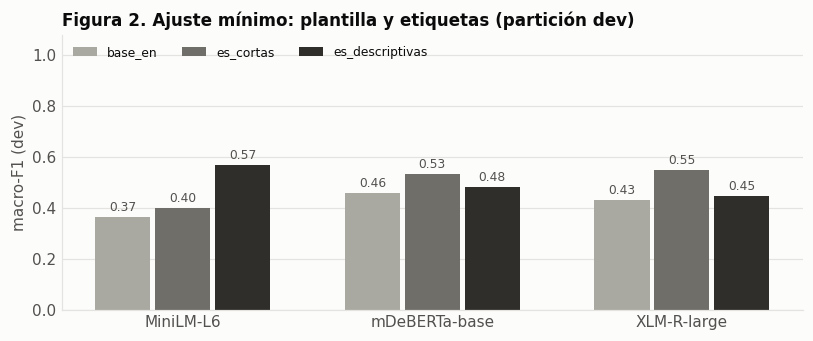

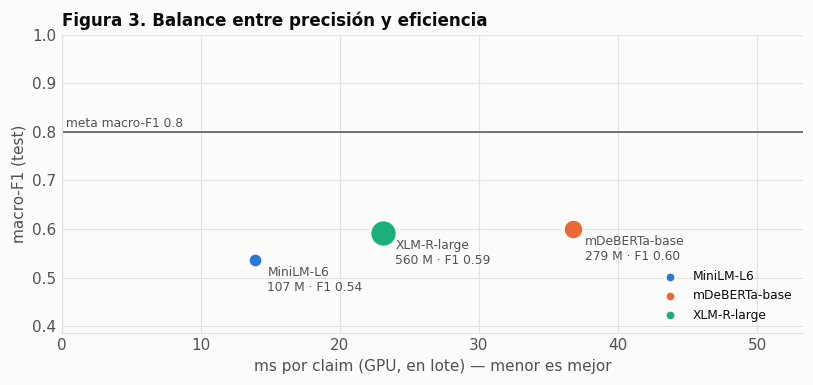

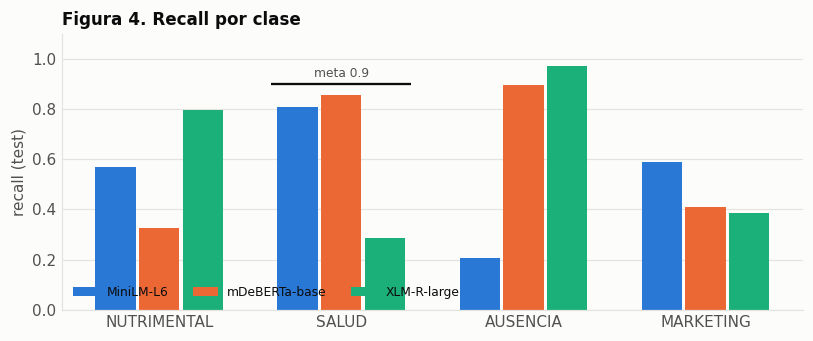

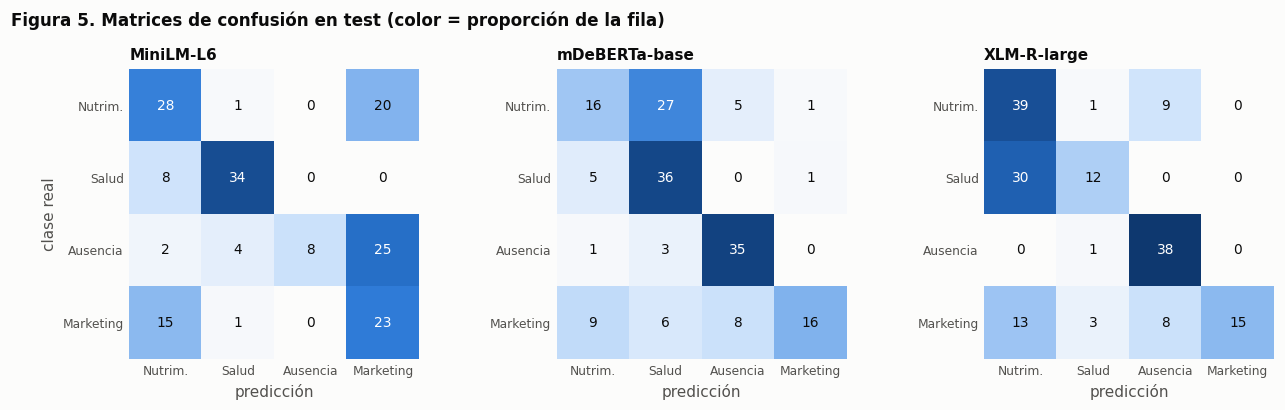

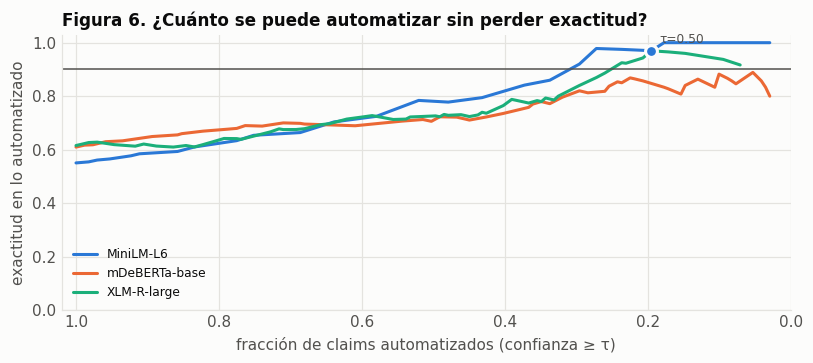

In [29]:
def _ejes_limpios(ax, eje="y"):
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
    ax.grid(axis=eje, color=REJILLA, linewidth=0.8); ax.set_axisbelow(True)
    ax.tick_params(length=0)


claves = list(RESULTADOS)

# Figura 2
fig, ax = plt.subplots(figsize=(7.5, 3.2))
x, ancho = np.arange(len(claves)), 0.24
for k, (nombre, color) in enumerate(COLOR_CONFIG.items()):
    vals = [ablacion_dev.query("modelo == @c and configuracion == @nombre")["f1_macro"].iloc[0] for c in claves]
    barras = ax.bar(x + (k - 1) * ancho, vals, ancho * 0.92, color=color, label=nombre)
    ax.bar_label(barras, fmt="%.2f", padding=2, fontsize=8, color=TINTA_2)
ax.set_xticks(x, claves); ax.set_ylim(0, 1.08); ax.set_ylabel("macro-F1 (dev)")
ax.set_title("Figura 2. Ajuste mínimo: plantilla y etiquetas (partición dev)")
ax.legend(ncol=3, loc="upper left", fontsize=8); _ejes_limpios(ax)
fig.tight_layout(); fig.savefig(DIR_FIGURAS / "fig2_ajuste_minimo_dev.png"); plt.show()

# Figura 3
usa_gpu = comparativo["ms_claim_gpu"].notna().all()
col_lat = "ms_claim_gpu" if usa_gpu else "ms_claim_cpu"
fig, ax = plt.subplots(figsize=(7.5, 3.6))
for c in claves:
    fila = comparativo.loc[c]
    ax.scatter(fila[col_lat], fila["f1_macro"], s=40 + fila["params_M"] / 2, color=COLOR_MODELO[c],
               edgecolor=SUPERFICIE, linewidth=2, zorder=3, label=c)
    ax.annotate(f"{c}\n{fila['params_M']:.0f} M · F1 {fila['f1_macro']:.2f}", (fila[col_lat], fila["f1_macro"]),
                xytext=(8, -4), textcoords="offset points", fontsize=8, color=TINTA_2, va="top")
ax.axhline(UMBRALES["f1_macro_min"], color=TINTA_2, linewidth=1)
ax.set_xlabel(f"ms por claim ({'GPU, en lote' if usa_gpu else 'CPU'}) — menor es mejor")
ax.set_ylabel("macro-F1 (test)"); ax.set_ylim(max(0, comparativo["f1_macro"].min() - 0.15), 1.0)
ax.set_xlim(0, comparativo[col_lat].max() * 1.45)
ax.text(0, UMBRALES["f1_macro_min"] + 0.01, f" meta macro-F1 {UMBRALES['f1_macro_min']}", fontsize=8, color=TINTA_2)
ax.set_title("Figura 3. Balance entre precisión y eficiencia")
ley = ax.legend(loc="lower right", fontsize=8)
for h in ley.legend_handles:
    h.set_sizes([50])
_ejes_limpios(ax, "both")
fig.tight_layout(); fig.savefig(DIR_FIGURAS / "fig3_tradeoff_precision_latencia.png"); plt.show()

# Figura 4
fig, ax = plt.subplots(figsize=(7.5, 3.2))
x, ancho = np.arange(len(CLASES)), 0.24
for k, c in enumerate(claves):
    vals = RESULTADOS[c]["por_clase"]["recall"].reindex(CLASES).to_numpy()
    ax.bar(x + (k - 1) * ancho, vals, ancho * 0.92, color=COLOR_MODELO[c], label=c)
i_salud = CLASES.index("SALUD")
ax.hlines(UMBRALES["recall_salud_min"], i_salud - 1.6 * ancho, i_salud + 1.6 * ancho, color=TINTA, linewidth=1.5)
ax.text(i_salud, UMBRALES["recall_salud_min"] + 0.03, f"meta {UMBRALES['recall_salud_min']}", ha="center",
        fontsize=8, color=TINTA_2)
ax.set_xticks(x, CLASES); ax.set_ylim(0, 1.1); ax.set_ylabel("recall (test)")
ax.set_title("Figura 4. Recall por clase"); ax.legend(ncol=3, loc="lower left", fontsize=8); _ejes_limpios(ax)
fig.tight_layout(); fig.savefig(DIR_FIGURAS / "fig4_recall_por_clase.png"); plt.show()

# Figura 5
ETIQ_CORTA = {"NUTRIMENTAL": "Nutrim.", "SALUD": "Salud", "AUSENCIA": "Ausencia", "MARKETING": "Marketing"}
azules = LinearSegmentedColormap.from_list("azul", ["#fcfcfb", "#cde2fb", "#86b6ef", "#2a78d6", "#184f95", "#0d366b"])
fig, axes = plt.subplots(1, len(claves), figsize=(4 * len(claves), 3.7))
axes = np.atleast_1d(axes)
for ax, c in zip(axes, claves):
    cm = RESULTADOS[c]["cm"]
    norm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
    ax.imshow(norm, cmap=azules, vmin=0, vmax=1)
    for i in range(len(CLASES)):
        for j in range(len(CLASES)):
            ax.text(j, i, f"{cm[i, j]}", ha="center", va="center", fontsize=9,
                    color="white" if norm[i, j] > 0.55 else TINTA)
    ax.set_xticks(range(len(CLASES)), [ETIQ_CORTA[k] for k in CLASES], fontsize=8)
    ax.set_yticks(range(len(CLASES)), [ETIQ_CORTA[k] for k in CLASES], fontsize=8)
    ax.set_xlabel("predicción"); ax.set_title(c, fontsize=10)
    for s in ax.spines.values():
        s.set_visible(False)
    ax.tick_params(length=0)
axes[0].set_ylabel("clase real")
fig.suptitle("Figura 5. Matrices de confusión en test (color = proporción de la fila)", x=0.01, ha="left",
             fontsize=11, fontweight="bold")
fig.tight_layout(); fig.savefig(DIR_FIGURAS / "fig5_matrices_confusion.png"); plt.show()

# Figura 6
fig, ax = plt.subplots(figsize=(7.5, 3.4))
for c in claves:
    p = RESULTADOS[c]["pred_test"]
    conf, corr = p["confianza"].to_numpy(), (p["pred"] == p["categoria"]).to_numpy()
    cov, acc = [], []
    for t in np.arange(0.25, 1.0, 0.01):
        m = conf >= t
        if m.sum() < 5:
            break
        cov.append(m.mean()); acc.append(corr[m].mean())
    ax.plot(cov, acc, color=COLOR_MODELO[c], linewidth=2, label=c, solid_capstyle="round")
    r = RESULTADOS[c]
    if r["tau"] is not None:
        ax.scatter(r["cobertura_auto"], r["exactitud_auto"], s=60, color=COLOR_MODELO[c],
                   edgecolor=SUPERFICIE, linewidth=2, zorder=3)
        ax.annotate(f"τ={r['tau']:.2f}", (r["cobertura_auto"], r["exactitud_auto"]), xytext=(5, 5),
                    textcoords="offset points", fontsize=8, color=TINTA_2)
ax.axhline(UMBRALES["precision_auto_min"], color=TINTA_2, linewidth=1)
ax.set_xlabel("fracción de claims automatizados (confianza ≥ τ)"); ax.set_ylabel("exactitud en lo automatizado")
ax.set_xlim(1.02, 0); ax.set_ylim(0, 1.03)
ax.set_title("Figura 6. ¿Cuánto se puede automatizar sin perder exactitud?")
ax.legend(loc="lower left", fontsize=8); _ejes_limpios(ax, "both")
fig.tight_layout(); fig.savefig(DIR_FIGURAS / "fig6_cobertura_vs_exactitud.png"); plt.show()

## 9. Selección del modelo recomendado

In [30]:
pasan = comparativo[comparativo["cumple_todo"]]
if len(pasan):
    mejor_f1 = pasan["f1_macro"].max()
    candidatos = pasan[pasan["f1_macro"] >= mejor_f1 - TOLERANCIA_F1]
    RECOMENDADO = candidatos.sort_values(["ms_claim_gpu", "ms_claim_cpu"]).index[0]
    VEREDICTO = ("cumple los tres umbrales de negocio; se recomienda para un piloto con revisión humana "
                 "de los claims por debajo de τ")
else:
    RECOMENDADO = comparativo.sort_values(["f1_macro", "ms_claim_cpu"], ascending=[False, True]).index[0]
    VEREDICTO = ("ningún modelo cumple todos los umbrales en zero-shot; se recomienda el de mayor macro-F1 "
                 "como base para fine-tuning con claims reales etiquetados y, mientras tanto, operar con "
                 "revisión humana de todo claim por debajo de τ")

rec = comparativo.loc[RECOMENDADO]
print(f"Modelo recomendado: {RECOMENDADO}  ({rec['model_id']})")
print(textwrap.fill(f"Veredicto: {VEREDICTO}.", 110))
print("\nRegla de decisión aplicada:")
print(f"  1) Filtrar modelos con macro-F1 ≥ {UMBRALES['f1_macro_min']}, recall SALUD ≥ {UMBRALES['recall_salud_min']}"
      f" y latencia ≤ {UMBRALES['latencia_gpu_max_ms']} ms/claim.")
print(f"  2) Entre los que cumplen, los que estén a ≤ {TOLERANCIA_F1} del mejor macro-F1 se consideran empate técnico.")
print("  3) Del empate, gana el de menor latencia (menor costo). Si ninguno cumple, gana el de mayor macro-F1.")
display(comparativo[["f1_macro", "recall_salud", "ms_claim_gpu", "ms_claim_cpu", "params_M",
                     "cumple_f1", "cumple_recall_salud", "cumple_latencia", "cumple_todo"]].round(3))

Modelo recomendado: mDeBERTa-base  (MoritzLaurer/mDeBERTa-v3-base-xnli-multilingual-nli-2mil7)
Veredicto: ningún modelo cumple todos los umbrales en zero-shot; se recomienda el de mayor macro-F1 como base
para fine-tuning con claims reales etiquetados y, mientras tanto, operar con revisión humana de todo claim por
debajo de τ.

Regla de decisión aplicada:
  1) Filtrar modelos con macro-F1 ≥ 0.8, recall SALUD ≥ 0.9 y latencia ≤ 300 ms/claim.
  2) Entre los que cumplen, los que estén a ≤ 0.02 del mejor macro-F1 se consideran empate técnico.
  3) Del empate, gana el de menor latencia (menor costo). Si ninguno cumple, gana el de mayor macro-F1.


,f1_macro,recall_salud,ms_claim_gpu,ms_claim_cpu,params_M,cumple_f1,cumple_recall_salud,cumple_latencia,cumple_todo
modelo,,,,,,,,,
MiniLM-L6,0.537,0.810,13.903,377.138,107,False,False,True,False
mDeBERTa-base,0.599,0.857,36.754,10641.958,279,False,False,True,False
XLM-R-large,0.592,0.286,23.118,1810.162,560,False,False,True,False


## 10. Análisis de errores del modelo recomendado

- Se revisa si los errores se concentran en los casos frontera (`ambiguo`) y si el desempeño difiere entre claims redactados a mano y generados por plantilla, lo que indicaría un sesgo del dataset.

In [31]:
p = RESULTADOS[RECOMENDADO]["pred_test"]
p = p.assign(acierto=p["pred"] == p["categoria"])
print(f"Errores de {RECOMENDADO}: {(~p['acierto']).sum()} de {len(p)} claims de test")
print("\nExactitud por dificultad y por origen del registro")
display(pd.concat({"dificultad": p.groupby("dificultad")["acierto"].agg(["mean", "size"]),
                   "origen": p.groupby("origen_registro")["acierto"].agg(["mean", "size"])}).round(3))
print("\nClaims mal clasificados (ordenados por confianza: los errores confiados son los más riesgosos)")
display(p.loc[~p["acierto"], ["id_claim", "texto_claim", "categoria", "pred", "confianza", "subtipo", "dificultad"]]
          .sort_values("confianza", ascending=False).round(3))

Errores de mDeBERTa-base: 66 de 169 claims de test

Exactitud por dificultad y por origen del registro


mean  size
dificultad ambiguo           0.655    29
           estandar          0.600   140
origen     plantilla         0.690    71
           redaccion_manual  0.551    98


Claims mal clasificados (ordenados por confianza: los errores confiados son los más riesgosos)


,id_claim,texto_claim,categoria,pred,confianza,subtipo,dificultad
65,CLM-0097,Hecho con ingredientes naturales,MARKETING,SALUD,0.934,marketing,ambiguo
75,CLM-0111,Una porción cubre el 50 % de tu requerimiento diario de vitamina C,NUTRIMENTAL,SALUD,0.832,cantidad_declarada,estandar
71,CLM-0107,Bajo en colesterol,NUTRIMENTAL,SALUD,0.797,contenido_bajo_o_sin,estandar
73,CLM-0109,Bajo en sodio,NUTRIMENTAL,SALUD,0.771,contenido_bajo_o_sin,estandar
113,CLM-0161,50 % menos sodio que la versión original,NUTRIMENTAL,SALUD,0.768,comparativa,estandar
...,...,...,...,...,...,...,...
44,CLM-0065,No contiene gluten,AUSENCIA,SALUD,0.317,gluten,estandar
8,CLM-0014,Receta original,MARKETING,NUTRIMENTAL,0.307,marketing,estandar
59,CLM-0086,Sin gluten,AUSENCIA,SALUD,0.296,gluten,estandar
7,CLM-0012,Listo en 3 minutos,MARKETING,AUSENCIA,0.288,marketing,estandar


## 11. Resultados

Se guardan CSV, resumen (JSON), entorno de ejecución y figuras en `results/`, y se descarga un ZIP para subirlo al GitHub.

In [32]:
import shutil

comparativo.to_csv(DIR_RESULTADOS / "metricas_modelos.csv")
ablacion_dev.to_csv(DIR_RESULTADOS / "ajuste_minimo_dev.csv", index=False)
por_clase.to_csv(DIR_RESULTADOS / "metricas_por_clase.csv")
predicciones.to_csv(DIR_RESULTADOS / "predicciones_test.csv", index=False)
META.to_csv(DIR_RESULTADOS / "metadatos_hub.csv")

entorno = {
    "fecha": datetime.now().isoformat(timespec="seconds"), "semilla": SEMILLA,
    "python": sys.version.split()[0], "plataforma": platform.platform(),
    "dispositivo": torch.cuda.get_device_name(0) if DEVICE == 0 else "CPU",
    "cuda": torch.version.cuda, "torch": torch.__version__, "transformers": transformers.__version__,
    "datasets": datasets.__version__, "evaluate": VERSION_EVALUATE, "huggingface_hub": huggingface_hub.__version__,
    "scikit_learn": sklearn.__version__, "batch_size": BATCH_SIZE,
    "commits_modelos": META["commit"].to_dict() if "commit" in META else {},
}
resumen = {
    "recomendado": RECOMENDADO, "veredicto": VEREDICTO, "umbrales": UMBRALES,
    "volumen_anual_claims": VOLUMEN_ANUAL_CLAIMS,
    "configuraciones": {k: {"plantilla": v["plantilla"], "etiquetas": v["etiquetas"]} for k, v in CONFIGURACIONES.items()},
    "modelos": json.loads(comparativo.to_json(orient="index")), "entorno": entorno,
}
(DIR_RESULTADOS / "resumen.json").write_text(json.dumps(resumen, ensure_ascii=False, indent=2), encoding="utf-8")
(DIR_RESULTADOS / "entorno.json").write_text(json.dumps(entorno, ensure_ascii=False, indent=2), encoding="utf-8")

archivo_zip = shutil.make_archive("resultados_actividad4", "zip", DIR_RESULTADOS)
print("Resultados guardados en", DIR_RESULTADOS.resolve())
for f in sorted(DIR_RESULTADOS.rglob("*")):
    if f.is_file():
        print("  ", f.relative_to(DIR_RESULTADOS))
try:
    from google.colab import files
    files.download(archivo_zip)
except ImportError:
    print("ZIP:", archivo_zip)

Resultados guardados en /content/results
   ajuste_minimo_dev.csv
   entorno.json
   figuras/fig1_distribucion_clases.png
   figuras/fig2_ajuste_minimo_dev.png
   figuras/fig3_tradeoff_precision_latencia.png
   figuras/fig4_recall_por_clase.png
   figuras/fig5_matrices_confusion.png
   figuras/fig6_cobertura_vs_exactitud.png
   metadatos_hub.csv
   metricas_modelos.csv
   metricas_por_clase.csv
   predicciones_test.csv
   resumen.json


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. Conclusiones

In [33]:
rec = comparativo.loc[RECOMENDADO]
ordenados = comparativo.sort_values("f1_macro", ascending=False)
mas_rapido = comparativo[col_lat].idxmin()
print("CONCLUSIONES (generadas a partir de las métricas de esta ejecución)\n")
puntos = [
    f"Desempeño: el ranking por macro-F1 en test es "
    + ", ".join(f"{k} ({v:.2f})" for k, v in ordenados["f1_macro"].items()) + ".",
    f"Eficiencia: {mas_rapido} es el más rápido ({comparativo.loc[mas_rapido, col_lat]:.1f} ms/claim). Al volumen anual "
    f"de {VOLUMEN_ANUAL_CLAIMS:,} claims, el recomendado requiere "
    + (f"{rec['horas_gpu_anuales']:.2f} h de GPU o " if pd.notna(rec["horas_gpu_anuales"]) else "")
    + f"{rec['horas_cpu_anuales']:.1f} h de CPU al año.",
    f"Ajuste mínimo: cambiar la plantilla de hipótesis y describir las clases según la guía de etiquetado movió el "
    f"macro-F1 del recomendado de {rec['f1_macro_sin_ajuste']:.2f} a {rec['f1_macro']:.2f}, sin reentrenar.",
    f"Recomendación: {RECOMENDADO} — {VEREDICTO}.",
    (f"Operación: con τ = {rec['tau']:.2f} se automatizaría el {rec['cobertura_auto']:.0%} de los claims con exactitud "
     f"{rec['exactitud_auto']:.0%}; el resto pasa a revisión humana." if pd.notna(rec["tau"])
     else "Operación: sin umbral que alcance la exactitud exigida; revisión humana del 100 %."),
]
for t in puntos:
    print(textwrap.fill("• " + t, 110, subsequent_indent="  "))

CONCLUSIONES (generadas a partir de las métricas de esta ejecución)

• Desempeño: el ranking por macro-F1 en test es mDeBERTa-base (0.60), XLM-R-large (0.59), MiniLM-L6 (0.54).
• Eficiencia: MiniLM-L6 es el más rápido (13.9 ms/claim). Al volumen anual de 86,400 claims, el recomendado
  requiere 0.88 h de GPU o 255.4 h de CPU al año.
• Ajuste mínimo: cambiar la plantilla de hipótesis y describir las clases según la guía de etiquetado movió el
  macro-F1 del recomendado de 0.56 a 0.60, sin reentrenar.
• Recomendación: mDeBERTa-base — ningún modelo cumple todos los umbrales en zero-shot; se recomienda el de
  mayor macro-F1 como base para fine-tuning con claims reales etiquetados y, mientras tanto, operar con
  revisión humana de todo claim por debajo de τ.
• Operación: sin umbral que alcance la exactitud exigida; revisión humana del 100 %.


### Conclusiones finales

- **Ningún modelo cumple los umbrales en zero-shot.** El mejor macro-F1 es 0.599 (mDeBERTa), lejos de la meta de 0.80, y ninguno llega a 0.90 de recall en SALUD.
- **Más allá de mDeBERTa, más tamaño no mejoró el macro-F1.** XLM-R large tiene el doble de parámetros y 3.5 veces la VRAM de mDeBERTa, y su macro-F1 es prácticamente igual (0.592).
- **La latencia no decide.** Los tres quedan muy por debajo de 300 ms por claim en lote. Las predicciones fueron idénticas en dos ejecuciones, pero la latencia de los modelos pequeños cambió (MiniLM 3.2 → 13.9 ms, mDeBERTa 7.4 → 36.8 ms) mientras XLM-R se mantuvo (23.0 → 23.1 ms), probablemente por la carga de CPU de la máquina compartida de Colab.
- **La accuracy no basta.** XLM-R tiene la mayor accuracy (0.615), pero envía 30 de 42 claims de salud a NUTRIMENTAL. La mayoría de los errores de mDeBERTa (36 de 66) van a SALUD, el checklist más estricto.
- **Ajuste mínimo:** la plantilla de hipótesis en español mejoró el macro-F1 de los tres modelos (+0.09, +0.04 y +0.14) sin reentrenar.
- **Recomendado: mDeBERTa-v3 base**, como base para fine-tuning con claims reales anonimizados. Mientras tanto, solo sugiere la clase y el revisor revisa el 100 %.
- **Nota sobre la latencia en CPU:** el valor de mDeBERTa (10,642 ms) es atípico y se repitió en las dos ejecuciones; la causa no se verificó y no se usa para decidir.